## Making traindata - 보간진행후 0,1 범위 밖값 갖는 window 없애서 데이터만듦 > 경로 data_without_outlier


In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import pandas as pd
import numpy as np
import scipy.signal as signal
import scipy.interpolate as interp
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# --- 2. GT 신호 필터링용 함수 (기존 코드 활용) ---
# def z_norm_vid(win_video, fill_value = -3.0) :


def butter_bandpass_filter(data, lowcut, highcut, fs, order=2):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    y = signal.filtfilt(b, a, data)
    return y

def z_norm(data):
    return (data - np.mean(data, axis = 0)) / (np.std(data, axis = 0) + 1e-8)

def z_norm_vid(win_video_interpolated, bg_fill_value=-3.0):

    is_valid = (win_video_interpolated != 0)
    
    is_background = ~is_valid

    valid_pixels = win_video_interpolated[is_valid]
    
    global_mean = np.mean(valid_pixels)
    global_std = np.std(valid_pixels) + 1e-8
    
    norm_video = (win_video_interpolated - global_mean) / global_std
    
    #  배경 위치(원래 배경 + 튀는 외삽 값)에 -3.0 덮어쓰기
    norm_video[is_background] = bg_fill_value 
    
    return norm_video

def z_norm_vid_out_of_bounds_bg(win_video_interpolated, bg_fill_value=-3.0):
    """
    유저의 관점 적용: 
    0.0 ~ 1.0 범위를 벗어난 외삽 노이즈와 원래 배경(0.0)을 모두 배경으로 취급하여 
    클리핑 없이 정규화 및 마스킹을 수행하는 함수
    """
    # 1. 유효 픽셀 및 배경 위치 파악 (클리핑 안 함)
    # 피부 픽셀의 조건: 1e-5 보다 크면서 1.0 이하인 값만 진짜 피부로 인정
    is_valid = (win_video_interpolated > 0 ) & (win_video_interpolated <= 1.0)
    
    # 위 조건에 맞지 않는 모든 픽셀(원래 배경 0.0 + 음수 오버슈팅 + 1.0 초과 오버슈팅)은 배경으로 간주
    is_background = ~is_valid
    
    # 2. 유효 픽셀(조건을 만족하는 피부)만 모아서 Z-norm 통계량 계산
    valid_pixels = win_video_interpolated[is_valid]
    
    # 만약 유효 픽셀이 하나도 없다면 전체를 배경값으로 반환
    if len(valid_pixels) == 0:
        return np.full_like(win_video_interpolated, bg_fill_value)
        
    global_mean = np.mean(valid_pixels)
    global_std = np.std(valid_pixels) + 1e-8
    
    # 3. 전체 비디오에 대해 Z-norm 수행 (클리핑되지 않은 원본 사용)
    # 어차피 배경 영역은 아래에서 덮어씌워지므로, 연산 편의를 위해 전체에 적용
    norm_video = (win_video_interpolated - global_mean) / global_std
    
    # 4. 배경 위치(원래 배경 + 튀는 외삽 값)에 -3.0 덮어쓰기
    norm_video[is_background] = bg_fill_value 
    
    return norm_video

# --- 3. 핵심 윈도우 처리 및 보간 함수 ---
def process_video_and_gt_windows(video_data, gt_ppg, sub_valid, window_size=900, max_gap_threshold=30):
    n_samples = len(video_data)
    n_windows = n_samples // window_size
    
    valid_vid_list = []
    valid_gt_list = []
    discarded_indices = []

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        win_video = video_data[start_idx:end_idx].copy()
        win_gt = gt_ppg[start_idx:end_idx].copy()
        win_valid = sub_valid[start_idx:end_idx].copy()
        
        # 결손(Gap) 길이 체크
        is_invalid = ~win_valid
        if np.any(is_invalid):
            condition = np.concatenate(([0], is_invalid, [0]))
            idx = np.flatnonzero(condition[1:] != condition[:-1])
            gap_lengths = idx[1::2] - idx[::2]
            max_gap = gap_lengths.max() if len(gap_lengths) > 0 else 0
        else:
            max_gap = 0
            
        # 임계치 30프레임(1초) 이상 시 폐기
        if max_gap >= max_gap_threshold:
            discarded_indices.append(i)
            continue
            
        try:
            # 보간(Interpolation) 수행
            if max_gap > 0:
                valid_idx = np.where(win_valid)[0]
                all_idx = np.arange(window_size)
                
                if len(valid_idx) > 1:
                    # 다차원 영상 PCHIP 보간
                    win_video = interp.pchip_interpolate(valid_idx, win_video[valid_idx], all_idx, axis=0)
                    

                else:
                    discarded_indices.append(i)
                    continue
            
            # --- 영상 전처리 ---
            #win_video_norm = z_norm_vid(win_video)
            
            # --- GT 전처리 ---
            # GT는 Detrend, Bandpass(0.75~2.5Hz), Z-norm 빡빡하게 적용
            detrend_gt = signal.detrend(win_gt)
            filter_gt = butter_bandpass_filter(detrend_gt, 0.75, 2.5, fs_video, order=2)
            win_gt_norm = z_norm(filter_gt)
            
            # 유효 리스트에 추가
            valid_vid_list.append(win_video)
            valid_gt_list.append(win_gt_norm)
            
        except Exception as e:
            print(f'Window {i} Error : {e}')
            discarded_indices.append(i)

    return valid_vid_list, valid_gt_list, discarded_indices



In [20]:
####################데이터 만든 코드 ########################################
################################################################################
#shift_frames = 400
fs_video = 30.0
fs_ppg = 500.0

# --- 1. 설정 및 파라미터 ---
people = ['A001_20250609', 'A002_20250609', 'A004_20250610', 'A005_20250611', 'A006_20250611', 
          'A007_20250612', 'A008_20250612', 'B001_20250623', 'B002_20250623', 'B003_20250624', 
          'B004_20250624', 'B005_20250625', 'B008_20250627', 'C001_20250701', 'C002_20250703', 'C003_20250702']

people_ppg = sorted([k.replace('_20', '_') for k in people]) 

preprocess_result_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/uv_registration_CNA'
ppg_cut_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_cut_final' # 실제 GT 경로로 수정 필요
final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier' # 최종 저장 폴더 (미리 생성 필요)
os.makedirs(final_save_dir, exist_ok= True)
# --- 3. 핵심 윈도우 처리 및 보간 함수 ---
def process_video_and_gt_windows(video_data, gt_ppg, sub_valid, window_size=900, max_gap_threshold=30):
    n_samples = len(video_data)
    n_windows = n_samples // window_size
    

    valid_vid_raw_list = []  # 검사용 (정규화 안됨)
    valid_gt_list = []
    discarded_indices = []

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        win_video = video_data[start_idx:end_idx].copy()
        win_gt = gt_ppg[start_idx:end_idx].copy()
        win_valid = sub_valid[start_idx:end_idx].copy()
        
        # 결손(Gap) 길이 체크
        is_invalid = ~win_valid
        if np.any(is_invalid):
            condition = np.concatenate(([0], is_invalid, [0]))
            idx = np.flatnonzero(condition[1:] != condition[:-1])
            gap_lengths = idx[1::2] - idx[::2]
            max_gap = gap_lengths.max() if len(gap_lengths) > 0 else 0
        else:
            max_gap = 0
            
        if max_gap >= max_gap_threshold:
            discarded_indices.append(i)
            continue
            
        try:
            # 보간(Interpolation) 수행
            if max_gap > 0:
                valid_idx = np.where(win_valid)[0]
                all_idx = np.arange(window_size)
                
                if len(valid_idx) > 1:
                    win_video = interp.pchip_interpolate(valid_idx, win_video[valid_idx], all_idx, axis=0)
                else:
                    discarded_indices.append(i)
                    continue
            
            # --- 영상 전처리 ---

            
            # --- GT 전처리 ---
            #detrend_gt = signal.detrend(win_gt)
            filter_gt = butter_bandpass_filter(win_gt, 0.75, 2.5, fs_video, order=2)
            win_gt_norm = z_norm(filter_gt)
            
            # 리스트에 추가 (검사용 Raw 데이터도 같이 저장)
            valid_vid_raw_list.append(win_video)       # 검사용 (0~1 확인용)

            valid_gt_list.append(win_gt_norm)
            
        except Exception as e:
            print(f'Window {i} Error : {e}')
            discarded_indices.append(i)

    # raw 리스트도 함께 반환
    return  valid_vid_raw_list, valid_gt_list, discarded_indices

# ==============================================================================
# 메인 반복문 부분
# ==============================================================================
total_dict = {i: '' for i in people}

# 변수명 충돌 방지를 위해 루프 변수 이름을 sub_idx로 변경
for sub_idx in range(len(people)):
    print(f"\n--- Processing {people[sub_idx]} ---")

    h5_video_path = os.path.join(preprocess_result_dir, f'registration_video_[{people[sub_idx]}].h5')
    with h5py.File(h5_video_path, 'r') as f_v:
        video_data = f_v['nir_uv_data'][:]
        sub_valid = f_v['valid_mask'][:]
        
    gt_csv_path = os.path.join(ppg_cut_dir, f'{people_ppg[sub_idx]}.csv')
    ppg_cut = pd.read_csv(gt_csv_path).values.flatten()

    # ppg_shift_samples = int(round((shift_frames / fs_video) * fs_ppg))
    # ppg_trimmed = ppg_cut[ppg_shift_samples:]
    # video_trimmed = video_data[:-shift_frames]
    # sub_valid_trimmed = sub_valid[:-shift_frames]

    ppg_downsampled = signal.resample(ppg_trimmed, len(video_trimmed))

    # 함수 반환값 4개로 변경됨
    valid_vid_raw_list, valid_gt_list, discarded = process_video_and_gt_windows(
        video_data=video_trimmed,
        gt_ppg=ppg_downsampled,
        sub_valid=sub_valid_trimmed,
        window_size=900,
        max_gap_threshold=30
    )

    indi_dict = {'num': 0, 'index': []}

    # 1. 검사용(Raw) 데이터를 기준으로 0 미만, 1 초과 윈도우 인덱스 찾기
    for w_idx in range(len(valid_vid_raw_list)):
        if np.max(valid_vid_raw_list[w_idx]) > 1.0 or np.min(valid_vid_raw_list[w_idx]) < 0.0:
            indi_dict['num'] += 1
            indi_dict['index'].append(w_idx)
            
    total_dict[people[sub_idx]] = indi_dict
    
    # 2. 불량 인덱스를 제외하고 최종 저장 리스트 만들기
    final_vid_list = []
    final_gt_list = []
    
    for w_idx in range(len(valid_vid_raw_list)):
        # 이상치 인덱스에 포함되지 않은 깨끗한 윈도우만 통과
        if w_idx not in indi_dict['index']:
            final_vid_list.append(valid_vid_raw_list[w_idx])
            final_gt_list.append(valid_gt_list[w_idx])
            
    # 3. 최종 H5 저장
    if len(final_vid_list) > 0:
        video_array = np.stack(final_vid_list)
        gt_array = np.stack(final_gt_list)
        
        final_h5_path = os.path.join(final_save_dir, f'final_dataset_{people[sub_idx]}.h5')
        with h5py.File(final_h5_path, 'w') as f_out:
            f_out.create_dataset('video', data=video_array, chunks=True, compression='gzip', compression_opts=4)
            f_out.create_dataset('gt_ppg', data=gt_array, chunks=True, compression='gzip', compression_opts=4)
            
        print(f"  -> 튀는 윈도우 {indi_dict['num']}개 제외 완료!")
        print(f"  -> 정상 윈도우 {len(final_vid_list)}개 저장 완료: {final_h5_path}")
    else:
        print(f"  -> 경고: 저장할 정상 윈도우가 하나도 없습니다!")


--- Processing A001_20250609 ---
  -> 튀는 윈도우 21개 제외 완료!
  -> 정상 윈도우 107개 저장 완료: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier/final_dataset_A001_20250609.h5

--- Processing A002_20250609 ---
  -> 튀는 윈도우 28개 제외 완료!
  -> 정상 윈도우 102개 저장 완료: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier/final_dataset_A002_20250609.h5

--- Processing A004_20250610 ---
  -> 튀는 윈도우 1개 제외 완료!
  -> 정상 윈도우 134개 저장 완료: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier/final_dataset_A004_20250610.h5

--- Processing A005_20250611 ---
  -> 튀는 윈도우 1개 제외 완료!
  -> 정상 윈도우 84개 저장 완료: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier/final_dataset_A005_20250611.h5

--- Processing A006_20250611 ---
  -> 튀는 윈도우 0개 제외 완료!
  -> 정상 윈도우 125개 저장 완료: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_d

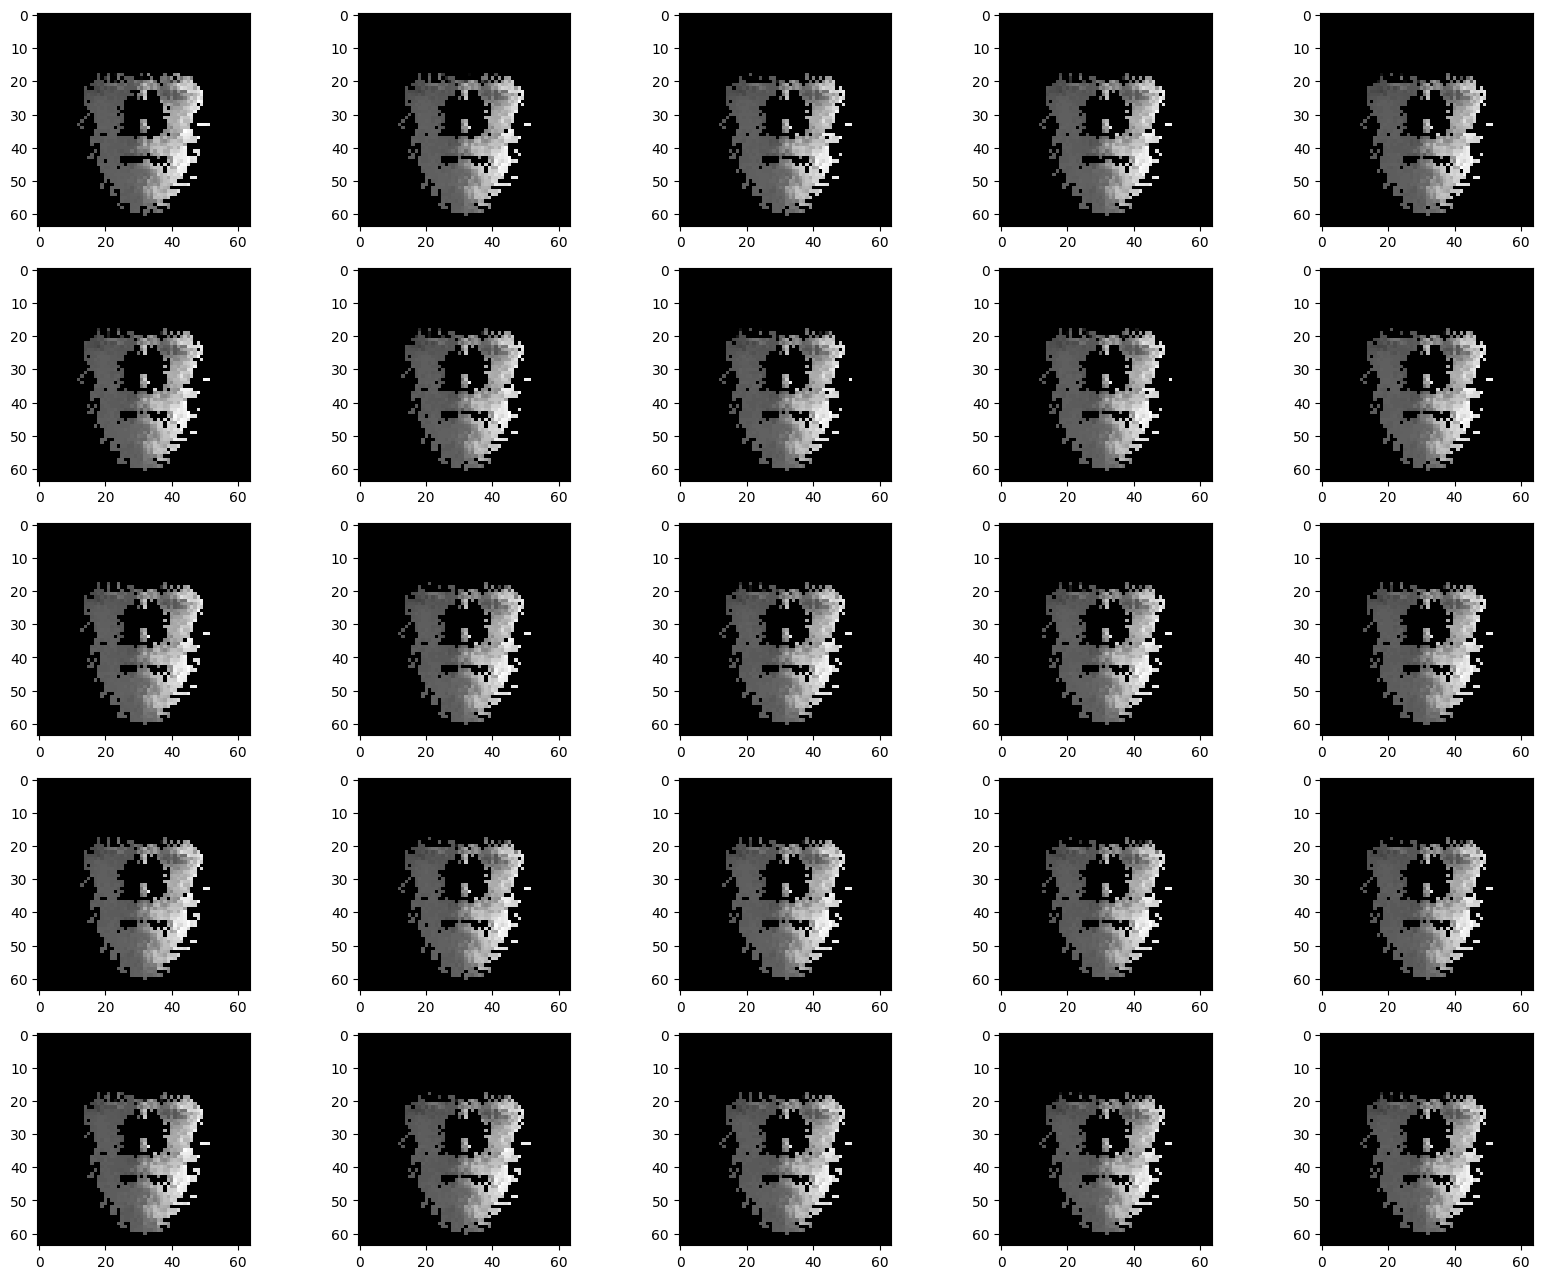

In [26]:
people = ['A001_20250609', 'A002_20250609', 'A004_20250610', 'A005_20250611', 'A006_20250611', 
          'A007_20250612', 'A008_20250612', 'B001_20250623', 'B002_20250623', 'B003_20250624', 
          'B004_20250624', 'B005_20250625', 'B008_20250627', 'C001_20250701', 'C002_20250703', 'C003_20250702']

final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier'

fig, axes = plt.subplots(5, 5, figsize=(20, 16))
axes = axes.flatten()

file_path = os.path.join(final_save_dir, f'final_dataset_A004_20250610.h5')
with h5py.File(file_path, 'r') as f:
    # 데이터 로드 (메모리 문제 시 [::2] 등 샘플링 적용)
    video_data = f['video'][:]  

for i in range(25) :
    ax = axes[i]
    ax.imshow(video_data[0,i,:,:], cmap = 'gray')
    

히스토그램 생성 중 (범위 확장 및 로그 스케일)...


100%|██████████| 16/16 [02:25<00:00,  9.11s/it]


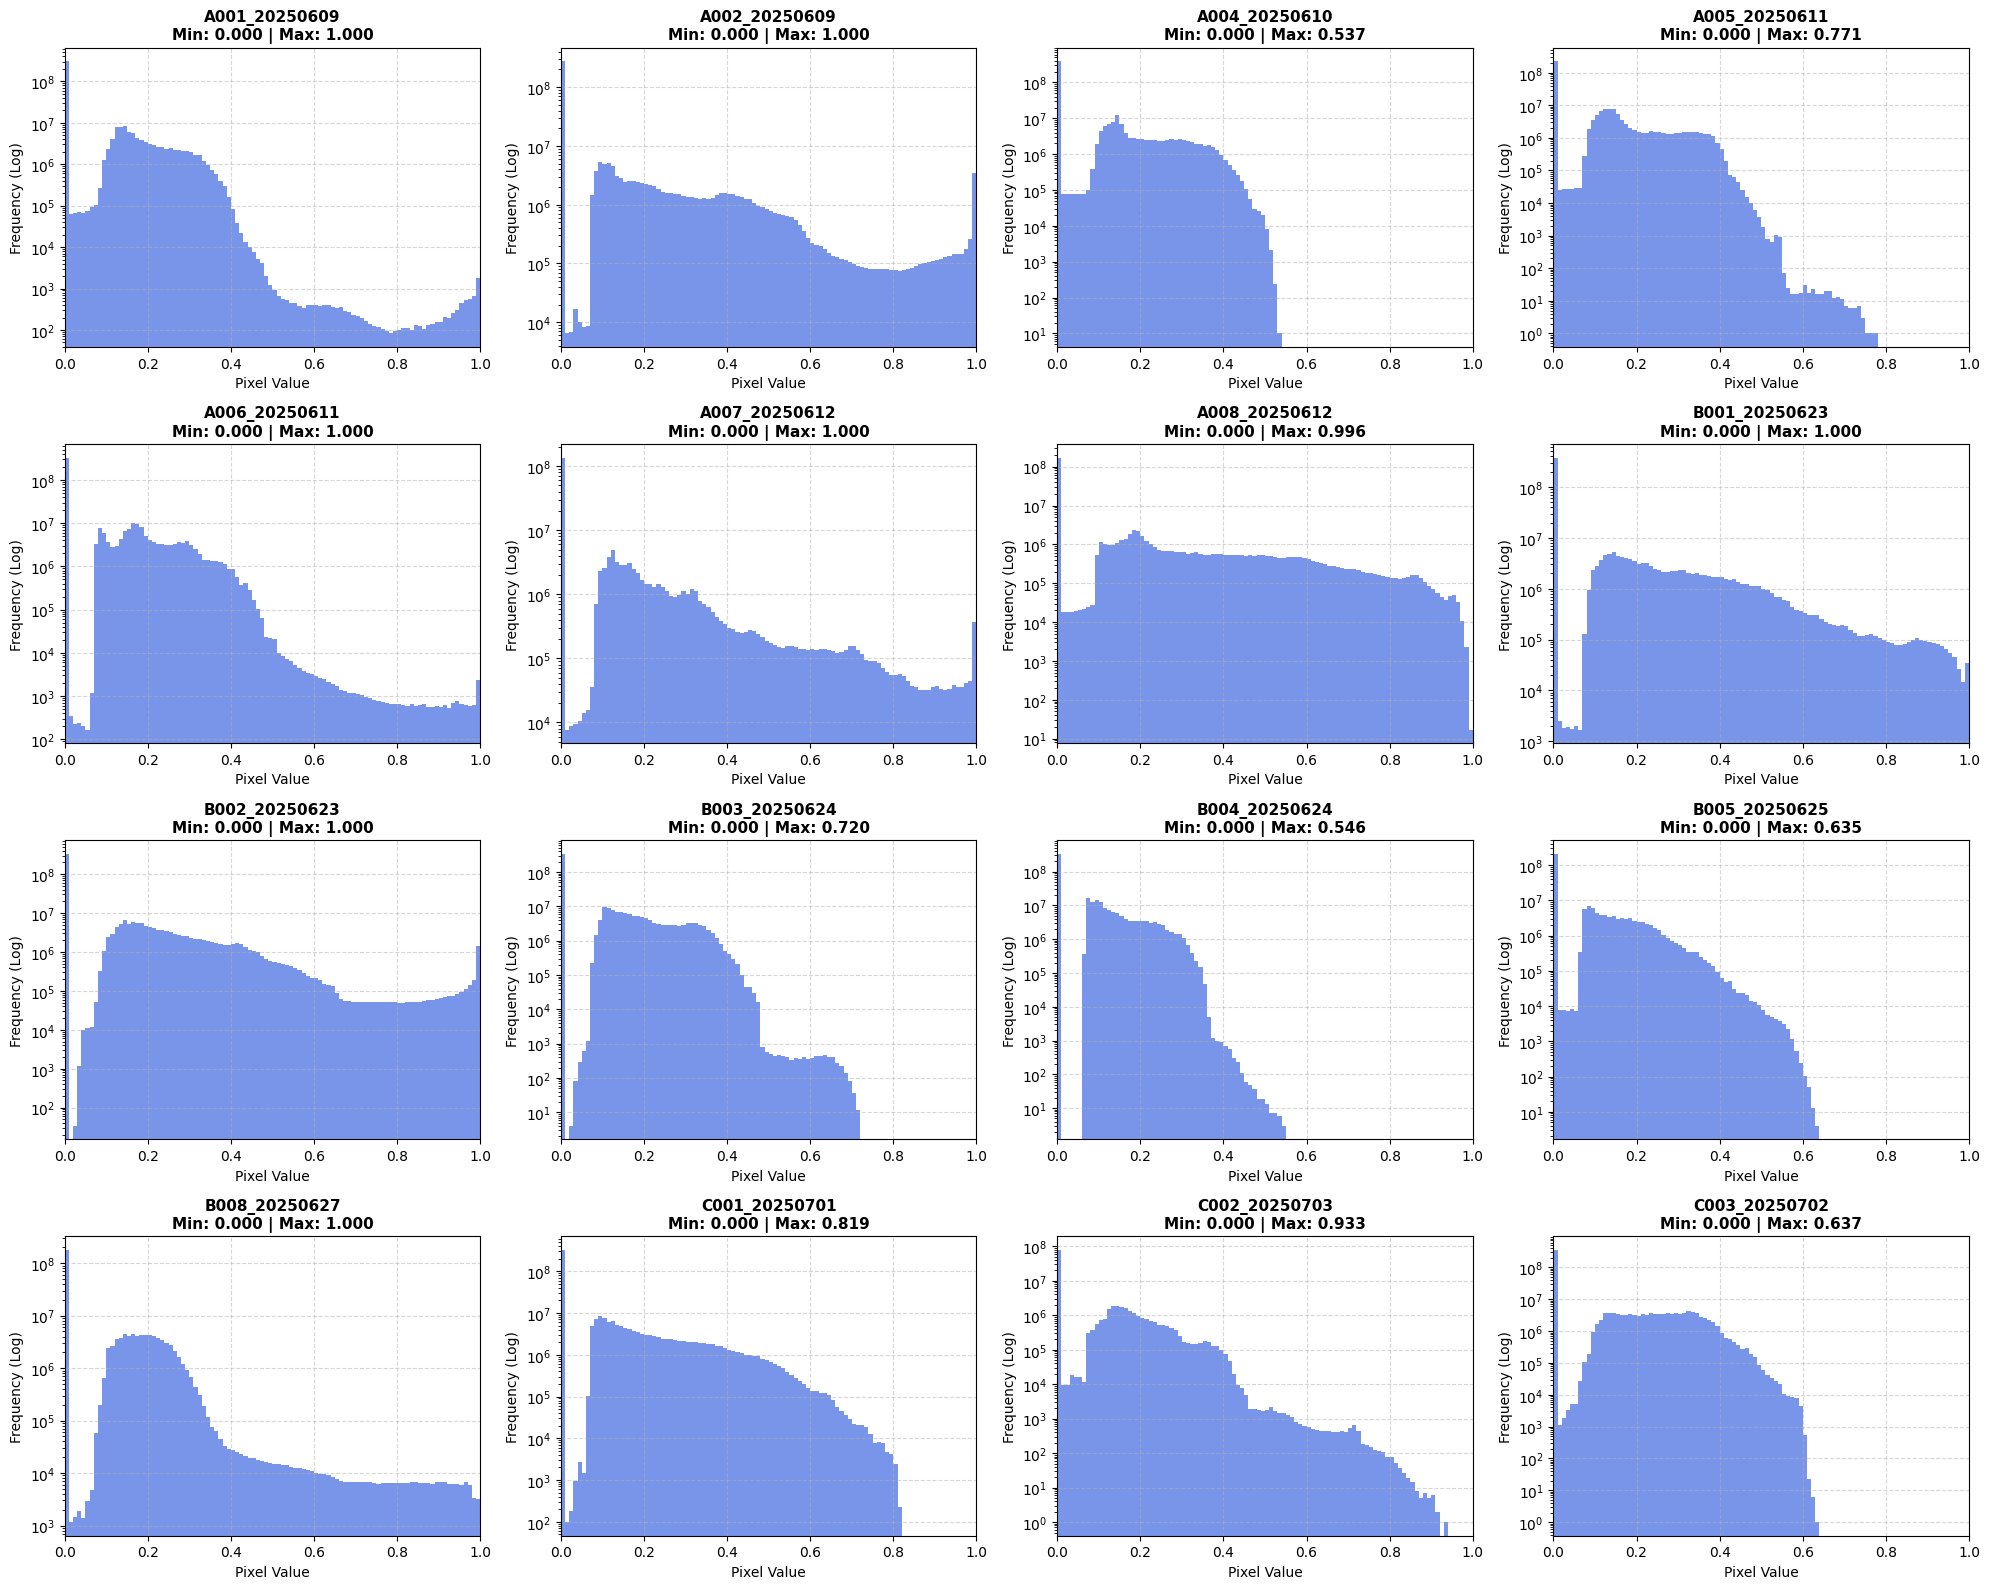

In [24]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- 1. 설정 및 파라미터 ---
people = ['A001_20250609', 'A002_20250609', 'A004_20250610', 'A005_20250611', 'A006_20250611', 
          'A007_20250612', 'A008_20250612', 'B001_20250623', 'B002_20250623', 'B003_20250624', 
          'B004_20250624', 'B005_20250625', 'B008_20250627', 'C001_20250701', 'C002_20250703', 'C003_20250702']

final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_without_outlier'

# --- 2. 4x4 플롯 설정 ---
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

print("히스토그램 생성 중 (범위 확장 및 로그 스케일)...")

for i, person in enumerate(tqdm(people)):
    file_path = os.path.join(final_save_dir, f'final_dataset_{person}.h5')
    ax = axes[i]
    
    if not os.path.exists(file_path):
        ax.text(0.5, 0.5, 'No Data', ha='center', va='center', fontsize=15, color='red')
        ax.set_title(person, fontsize=12)
        ax.set_xlim(0, 1.0)
        continue
        
    with h5py.File(file_path, 'r') as f:
        # 데이터 로드 (메모리 문제 시 [::2] 등 샘플링 적용)
        video_data = f['video'][:]  
        vid_flat = video_data.flatten()
        
        # 실제 데이터의 최소, 최대값 계산
        val_min = np.min(vid_flat)
        val_max = np.max(vid_flat)
        
        # 히스토그램 그리기 (범위를 -0.5 ~ 1.5로 확장)
        # 만약 이 범위를 넘어가는 극단적인 값이 있다면 range를 아예 빼버려도 됩니다.
        ax.hist(vid_flat, bins=100, range=(0, 1.0), color='royalblue', alpha=0.7, log=True)
        
        # 제목에 Min/Max 수치 표시 (소수점 3자리까지)
        title_text = f"{person}\nMin: {val_min:.3f} | Max: {val_max:.3f}"
        
        # 만약 0.0 미만이나 1.0 초과 값이 있다면 제목을 빨간색으로 표시
        if val_min < 0.0 or val_max > 1.0:
            ax.set_title(title_text, fontsize=11, fontweight='bold', color='red')
        else:
            ax.set_title(title_text, fontsize=11, fontweight='bold', color='black')
            
        ax.set_xlim(0, 1.0) 
        ax.set_xlabel('Pixel Value')
        ax.set_ylabel('Frequency (Log)')
        ax.grid(True, linestyle='--', alpha=0.5)

# 레이아웃 간격 조정 및 저장
plt.tight_layout()


plt.show()

In [12]:
import pandas as pd
from IPython.display import display

# DataFrame 생성을 위한 리스트 형태 전처리
df_data = []
for person, info in total_dict.items():
    if isinstance(info, dict):
        df_data.append({
            'Subject ID': person,
            '이상 윈도우 개수 (num)': info['num'],
            '해당 윈도우 인덱스 (index)': str(info['index']) # 보기 좋게 문자열로 변환
        })
    else:
        # 데이터가 비어있거나 에러로 인해 처리되지 않은 Subject
        df_data.append({
            'Subject ID': person,
            '이상 윈도우 개수 (num)': 0,
            '해당 윈도우 인덱스 (index)': '[]'
        })

# Pandas DataFrame 생성
df = pd.DataFrame(df_data)

# 인덱스를 1부터 시작하게 설정 (선택 사항)
df.index = np.arange(1, len(df) + 1)

# 보기 좋게 출력 (Jupyter Notebook 환경에서는 예쁜 표 형태로 나옵니다)
print("\n=======================================================")
print("🎯 [결과 요약] Subject별 0, 1 범위 이탈 윈도우 통계 (DataFrame)")
print("=======================================================")
display(df)


🎯 [결과 요약] Subject별 0, 1 범위 이탈 윈도우 통계 (DataFrame)


,Subject ID,이상 윈도우 개수 (num),해당 윈도우 인덱스 (index)
1,A001_20250609,21,"[2, 4, 5, 27, 31, 34, 38, 48, 51, 52, 53, 54, ..."
2,A002_20250609,28,"[43, 44, 51, 53, 55, 57, 58, 59, 61, 63, 64, 6..."
3,A004_20250610,1,[134]
4,A005_20250611,1,[0]
5,A006_20250611,0,[]
6,A007_20250612,35,"[31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 4..."
7,A008_20250612,17,"[0, 1, 10, 12, 14, 18, 19, 20, 26, 33, 43, 48,..."
8,B001_20250623,1,[1]
9,B002_20250623,17,"[106, 113, 114, 115, 116, 117, 118, 119, 120, ..."
10,B003_20250624,0,[]


### checking values perframe

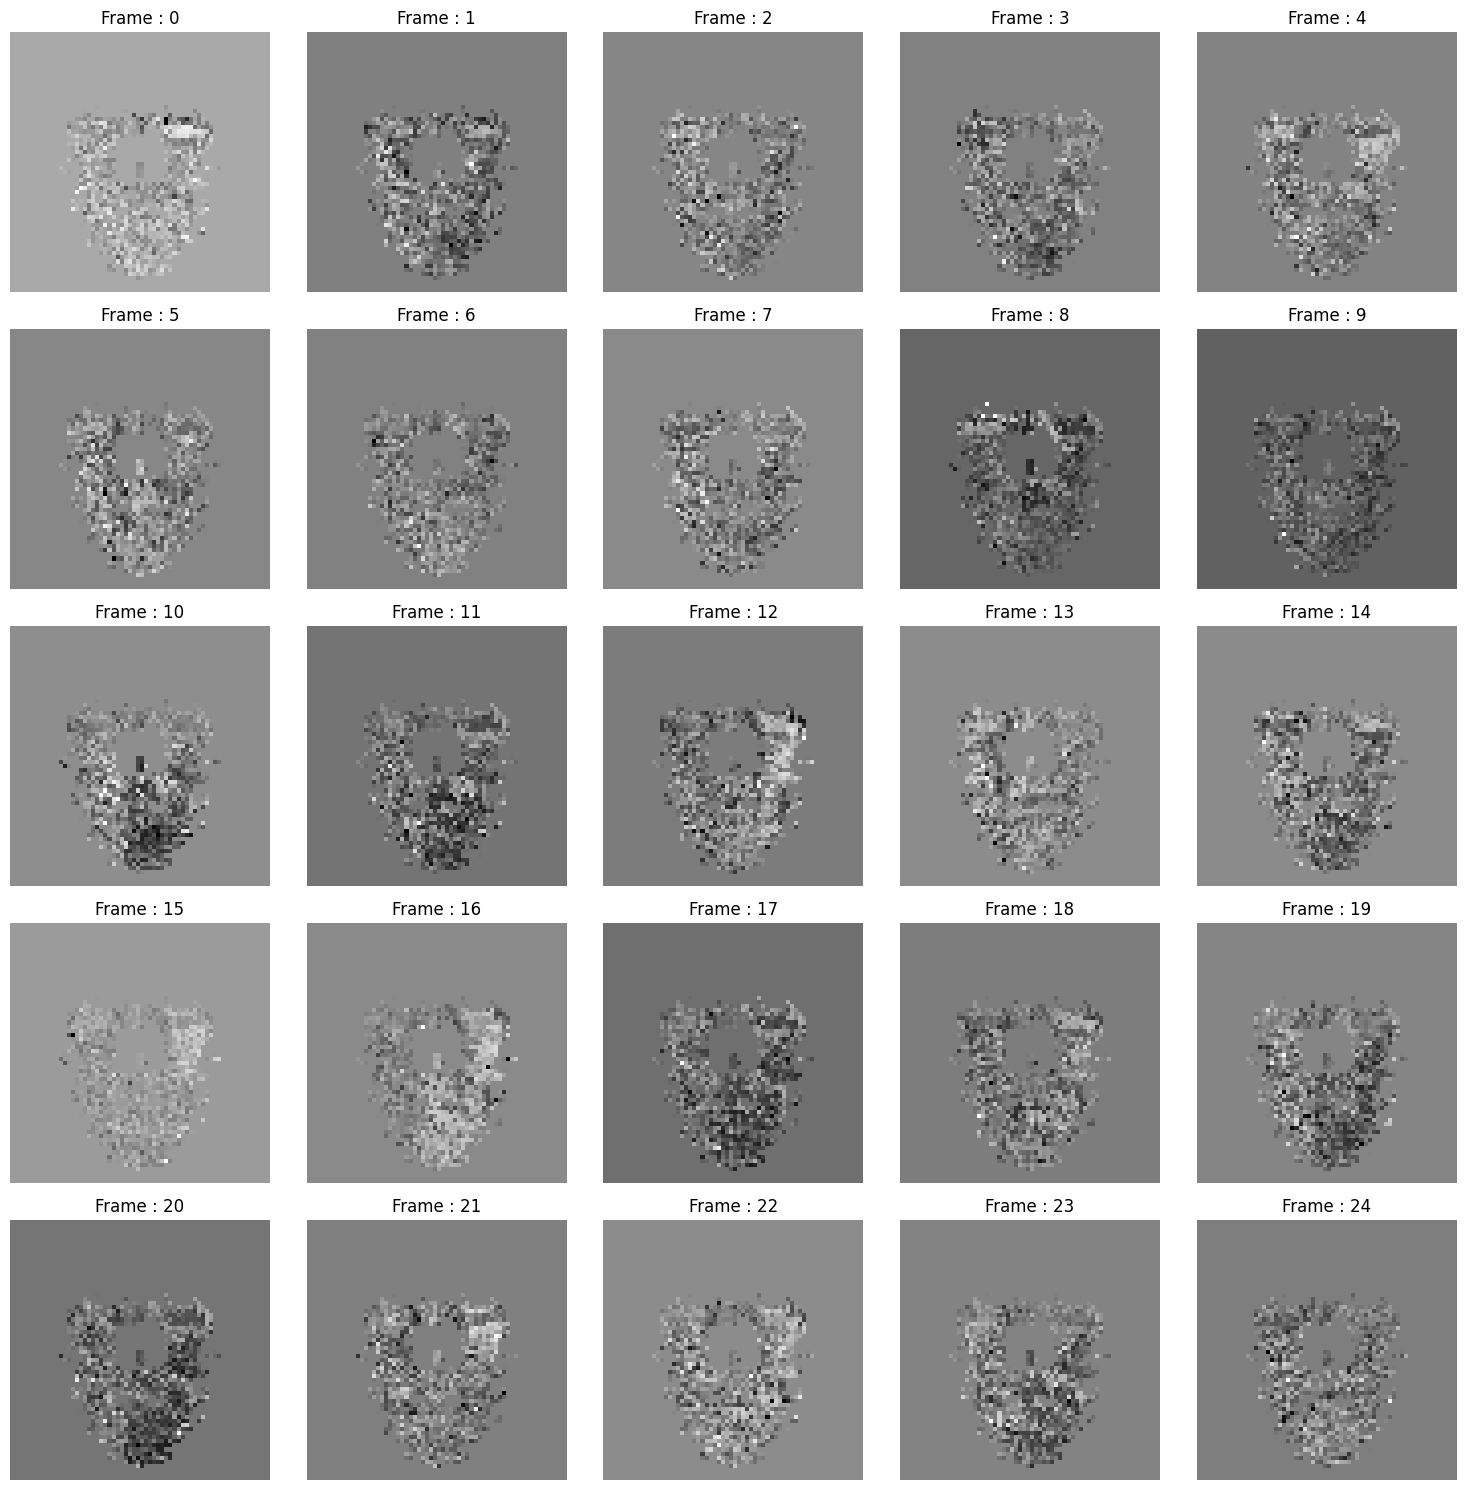

In [26]:
v1 = valid_vid['A004']
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, f in enumerate(v1[54][:25]):
        
    axes[i].imshow(f, cmap='gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


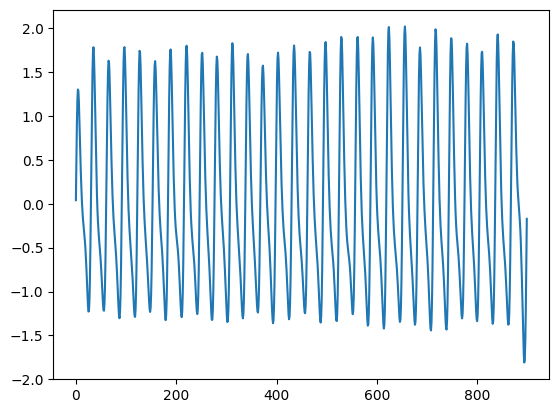

In [37]:
vp1 = valid_ppg['A004']
plt.plot(vp1[0])


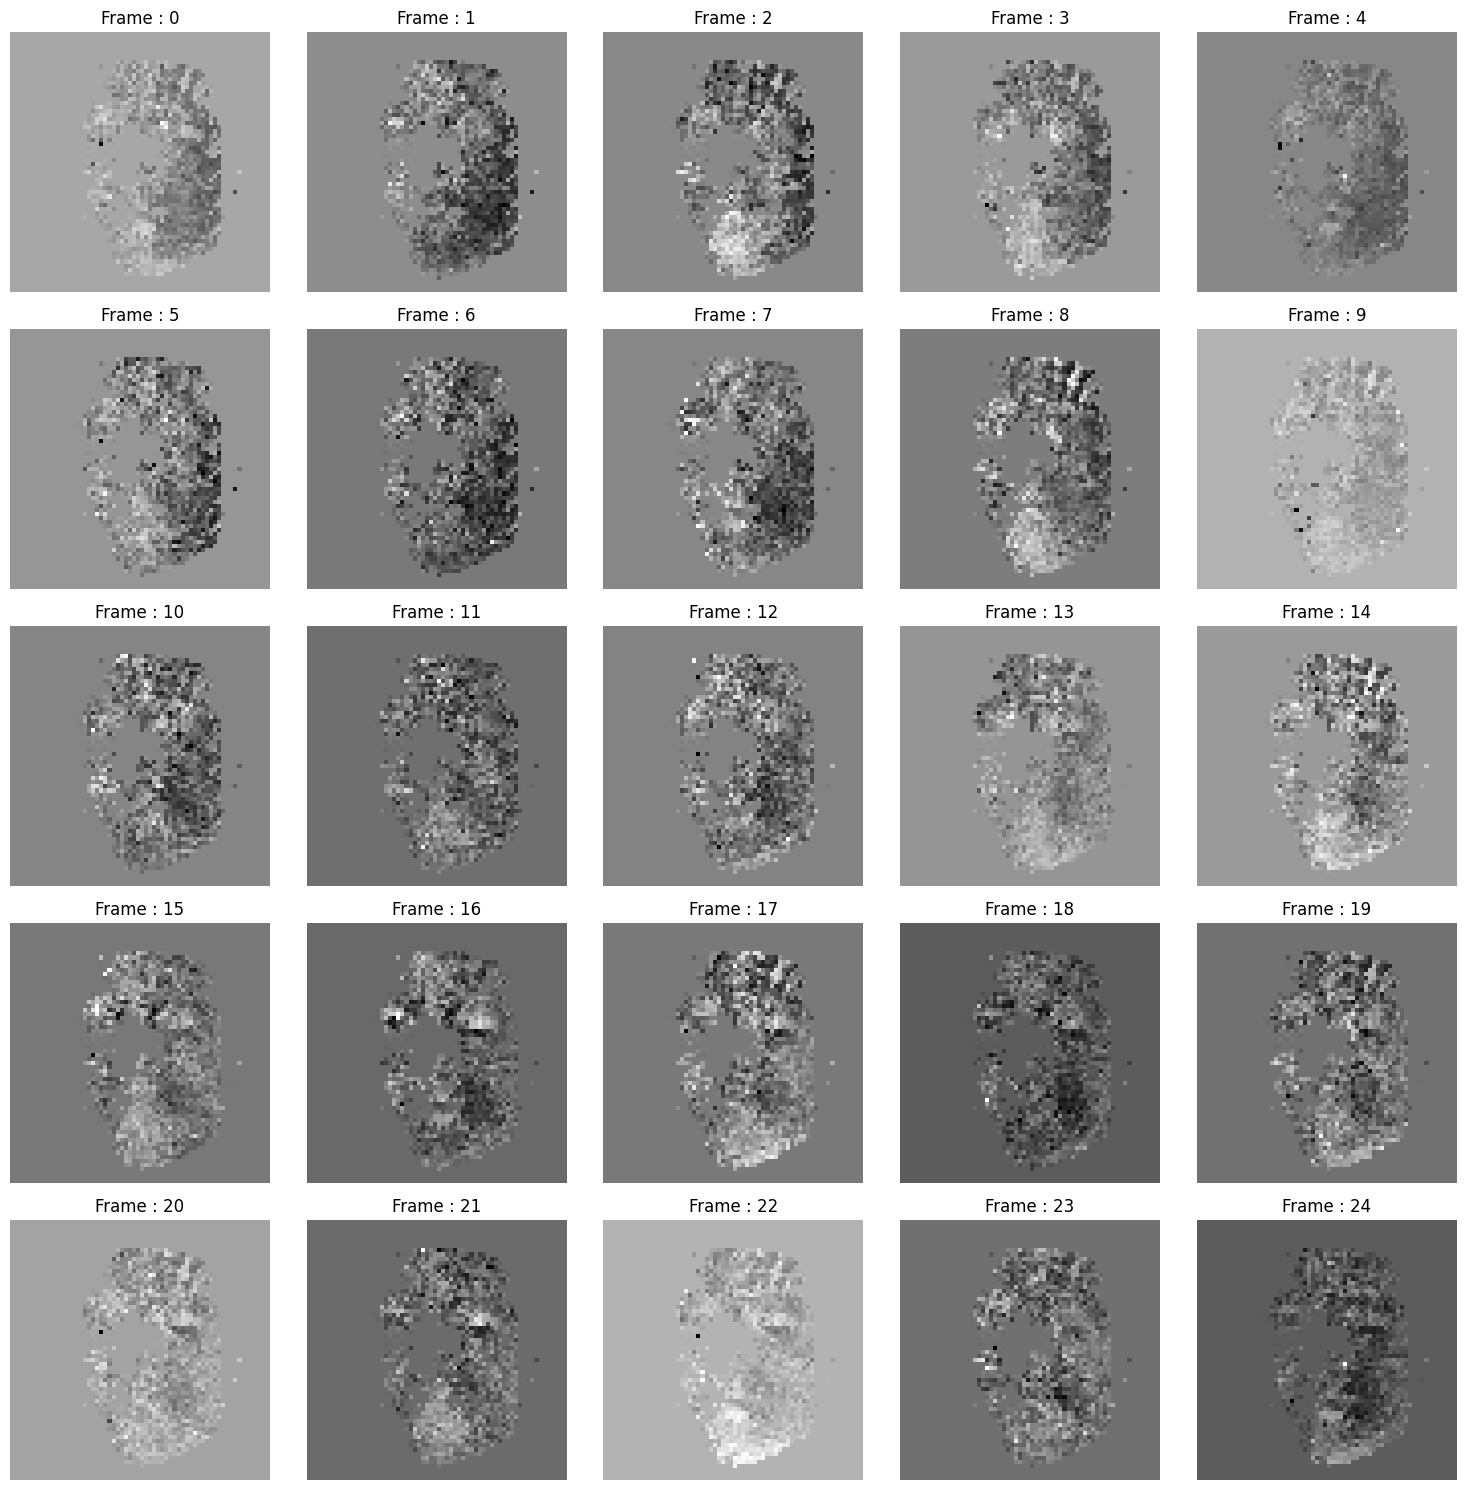

In [38]:
v1 = train_vid['B003']
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, f in enumerate(v1[1][25:50]):
        
    axes[i].imshow(f, cmap='gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


In [39]:
print("=== Train Video Data 통계 ===")
for k in train_vid:
    video_array = train_vid[k]
    
    print(f"[Train Sub: {k}]")
    print(f"  - Shape: {video_array.shape}")
    print(f"  - Min: {np.min(video_array):.4f} | Max: {np.max(video_array):.4f}")
    print(f"  - Mean: {np.mean(video_array):.4f} | Std: {np.std(video_array):.4f}")
    print("-" * 30)

=== Train Video Data 통계 ===
[Train Sub: A006]
  - Shape: (125, 900, 64, 64)
  - Min: -29.5002 | Max: 29.9847
  - Mean: 0.0000 | Std: 0.5583
------------------------------
[Train Sub: A007]
  - Shape: (88, 900, 64, 64)
  - Min: -29.9833 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5817
------------------------------
[Train Sub: A008]
  - Shape: (76, 900, 64, 64)
  - Min: -29.6341 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.5395
------------------------------
[Train Sub: B001]
  - Shape: (135, 900, 64, 64)
  - Min: -29.8630 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5232
------------------------------
[Train Sub: B002]
  - Shape: (140, 900, 64, 64)
  - Min: -29.9831 | Max: 29.9840
  - Mean: -0.0000 | Std: 0.5660
------------------------------
[Train Sub: B003]
  - Shape: (127, 900, 64, 64)
  - Min: -29.6686 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5403
------------------------------
[Train Sub: B004]
  - Shape: (127, 900, 64, 64)
  - Min: -29.9829 | Max: 29.9840
  - Mean: 0.0001 | Std: 0.5576
---

In [40]:
print("\n=== Validation Video Data 통계 ===")
for j in valid_vid:
    video_array = valid_vid[j]
    
    print(f"[Valid Sub: {j}]")
    print(f"  - Shape: {video_array.shape}")
    print(f"  - Min: {np.min(video_array):.4f} | Max: {np.max(video_array):.4f}")
    print(f"  - Mean: {np.mean(video_array):.4f} | Std: {np.std(video_array):.4f}")
    print("-" * 30)


=== Validation Video Data 통계 ===
[Valid Sub: A004]
  - Shape: (135, 900, 64, 64)
  - Min: -29.4912 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.4833
------------------------------
[Valid Sub: A005]
  - Shape: (85, 900, 64, 64)
  - Min: -29.4527 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.5446
------------------------------


In [13]:
final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data' # 최종 저장 폴더 (미리 생성 필요)
ff = os.path.join(final_save_dir, 'data_without_outlier')
ppp = sorted(os.listdir(ff))

for name in ppp :
    with h5py.File(os.path.join(ff, name ), 'r') as f_v:
        video_data = f_v['video'][:]
        sub_valid = f_v['gt_ppg'][:]
        print(f'{name}  :  {video_data.shape}')


final_dataset_A001_20250609.h5  :  (107, 900, 64, 64)
final_dataset_A002_20250609.h5  :  (102, 900, 64, 64)
final_dataset_A004_20250610.h5  :  (134, 900, 64, 64)
final_dataset_A005_20250611.h5  :  (84, 900, 64, 64)
final_dataset_A006_20250611.h5  :  (125, 900, 64, 64)
final_dataset_A007_20250612.h5  :  (53, 900, 64, 64)
final_dataset_A008_20250612.h5  :  (59, 900, 64, 64)
final_dataset_B001_20250623.h5  :  (134, 900, 64, 64)
final_dataset_B002_20250623.h5  :  (123, 900, 64, 64)
final_dataset_B003_20250624.h5  :  (127, 900, 64, 64)
final_dataset_B004_20250624.h5  :  (126, 900, 64, 64)
final_dataset_B005_20250625.h5  :  (76, 900, 64, 64)
final_dataset_B008_20250627.h5  :  (67, 900, 64, 64)
final_dataset_C001_20250701.h5  :  (122, 900, 64, 64)
final_dataset_C002_20250703.h5  :  (27, 900, 64, 64)
final_dataset_C003_20250702.h5  :  (122, 900, 64, 64)


In [18]:
final_save_dirrr = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_for_dl' # 최종 저장 폴더 (미리 생성 필요)

ppp = sorted(os.listdir(final_save_dirrr))
ppp = [ii for ii in ppp if ii.endswith('h5')]

for name in ppp :
    with h5py.File(os.path.join(final_save_dirrr, name ), 'r') as f_v:
        video_data = f_v['video'][:]

        print(f'{name}  :  {video_data.shape}')

final_dataset_A001_20250609.h5  :  (128, 900, 64, 64)
final_dataset_A002_20250609.h5  :  (130, 900, 64, 64)
final_dataset_A004_20250610.h5  :  (135, 900, 64, 64)
final_dataset_A005_20250611.h5  :  (85, 900, 64, 64)
final_dataset_A006_20250611.h5  :  (125, 900, 64, 64)
final_dataset_A007_20250612.h5  :  (88, 900, 64, 64)
final_dataset_A008_20250612.h5  :  (76, 900, 64, 64)
final_dataset_B001_20250623.h5  :  (135, 900, 64, 64)
final_dataset_B002_20250623.h5  :  (140, 900, 64, 64)
final_dataset_B003_20250624.h5  :  (127, 900, 64, 64)
final_dataset_B004_20250624.h5  :  (127, 900, 64, 64)
final_dataset_B005_20250625.h5  :  (77, 900, 64, 64)
final_dataset_B008_20250627.h5  :  (86, 900, 64, 64)
final_dataset_C001_20250701.h5  :  (122, 900, 64, 64)
final_dataset_C002_20250703.h5  :  (37, 900, 64, 64)
final_dataset_C003_20250702.h5  :  (126, 900, 64, 64)
